# Bangkok CCTV traffic: analysis
**Question:** where and when does Bangkok traffic get busy, and what does rain do to it?

Reads the gold tables in `export/` (built by `uv run python -m pipeline.flow`). 100 cameras, 25–31 Aug 2026, one image every 10 min, 06:00–21:00.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf

EXPORT = Path("../export") if Path("../export").exists() else Path("export")
hourly = pd.read_parquet(EXPORT / "camera_hour.parquet")
cams = pd.read_parquet(EXPORT / "cameras.parquet").merge(pd.read_parquet(EXPORT / "camera_clusters.parquet"), on="camera_id", how="left")
hourly["date"] = hourly.hour.dt.date
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": .3})
print(len(hourly), "camera-hours;", int(hourly.n_images.sum()), "images;", int(hourly.n_valid.sum()), "usable")
hourly[["pcu", "n_car", "n_motorcycle", "n_bus", "n_person", "precipitation", "pm2_5"]].describe().round(2)

10728 camera-hours; 61319 images; 60222 usable


,pcu,n_car,n_motorcycle,n_bus,n_person,precipitation,pm2_5
count,10125.00,10125.00,10125.00,10125.00,10125.00,10728.00,10728.00
mean,6.86,5.90,0.66,0.29,1.08,0.31,6.54
std,4.39,3.73,1.06,0.43,1.20,1.70,4.56
min,0.00,0.00,0.00,0.00,0.00,0.00,1.80
25%,3.50,3.00,0.00,0.00,0.17,0.00,3.70
50%,6.25,5.33,0.17,0.17,0.67,0.00,5.10
75%,9.42,8.33,0.83,0.33,1.60,0.00,7.90
max,27.36,21.00,9.00,4.60,11.67,27.50,45.10


## 1. When: the shape of a day
`pcu` = vehicles in view (motorcycle 0.33, car 1, bus 2.5; YOLO's "truck" counts as a car). The drop after 18:00 is at least partly YOLO missing vehicles in the dark, so compare hours within daylight (07–17) only.

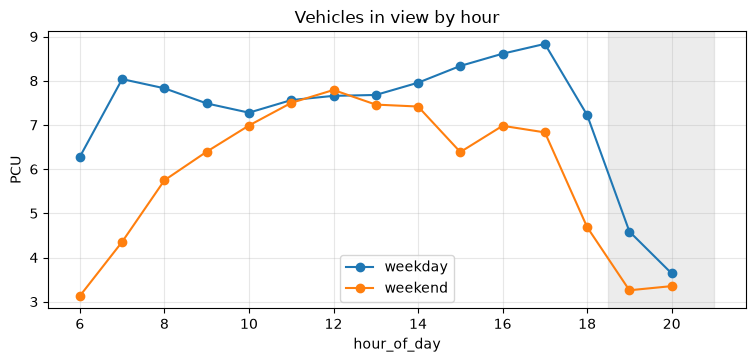

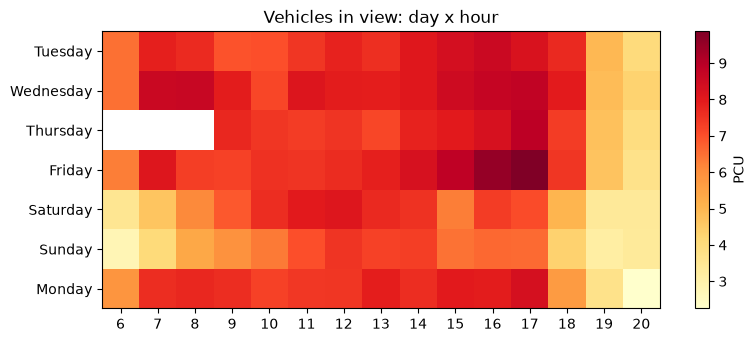

daylight mean PCU  weekday 7.93  weekend 6.71
{'Tuesday': 7.76, 'Wednesday': 8.22, 'Thursday': 7.79, 'Friday': 8.16, 'Saturday': 7.02, 'Sunday': 6.41, 'Monday': 7.71}


In [2]:
day = hourly.groupby(["hour_of_day", "is_weekend"]).pcu.mean().unstack()
day.columns = ["weekday", "weekend"]
ax = day.plot(marker="o", title="Vehicles in view by hour"); ax.axvspan(18.5, 21, color="grey", alpha=.15); ax.set_ylabel("PCU"); plt.show()
order = ["Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday", "Monday"]
heat = hourly.pivot_table(index="weekday", columns="hour_of_day", values="pcu").reindex(order)
plt.imshow(heat, aspect="auto", cmap="YlOrRd"); plt.yticks(range(7), order); plt.xticks(range(len(heat.columns)), heat.columns)
plt.colorbar(label="PCU"); plt.title("Vehicles in view: day x hour"); plt.grid(False); plt.show()
light = hourly[hourly.hour_of_day.between(7, 17)]
print("daylight mean PCU  weekday %.2f  weekend %.2f" % (light[~light.is_weekend].pcu.mean(), light[light.is_weekend].pcu.mean()))
print(light.groupby("weekday").pcu.mean().reindex(order).round(2).to_dict())

## 2. Where: busiest cameras and road types

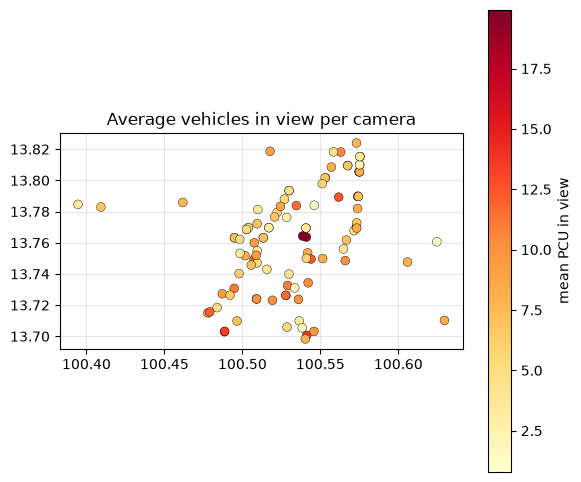

                                                      name road_class  lanes  mean_pcu
            Footbridge near Soi Rang Nam on Phayathai Road    primary    7.0      19.9
   Traffic Lights near Soi Rajavithi  6 on Rajavithi  Road    primary    2.0      18.9
                near the police box on Thiam Ruam Mit Road   tertiary    3.0      18.9
      Near Pao Leng Pharmacy on Mahai Sawan Road (Inbound)  secondary    NaN      14.2
                     Under the overpass on Narathiwas Road  secondary    NaN      13.8
         Near the police box on Mahai Sawan Road (Inbound)  secondary    NaN      13.6
Central barrier near the police box on Ratchadaphisek Road    primary    4.0      12.5
                                    Sutthisan Intersection  secondary    NaN      12.4


,cameras,mean_pcu,motorcycle_share
road_class,,,
primary,42,7.52,0.04
residential,2,3.82,0.08
secondary,42,7.51,0.15
tertiary,10,7.81,0.11
trunk,2,5.19,0.01
unclassified,2,6.53,0.08


In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(cams.longitude, cams.latitude, c=cams.mean_pcu, s=40, cmap="YlOrRd", edgecolor="k", linewidth=.3)
plt.colorbar(sc, label="mean PCU in view"); ax.set_title("Average vehicles in view per camera"); ax.set_aspect("equal"); plt.show()
print(cams.nlargest(8, "mean_pcu")[["name", "road_class", "lanes", "mean_pcu"]].round(1).to_string(index=False))
cams.groupby("road_class").agg(cameras=("camera_id", "size"), mean_pcu=("mean_pcu", "mean"), motorcycle_share=("mean_motorcycle_share", "mean")).round(2)

## 3. Camera groups (K-means on the daily shape)
Each camera's congestion z-score by hour (06–20) is clustered. Silhouette is only about 0.22, so the groups overlap: treat them as a description, not sharp types.

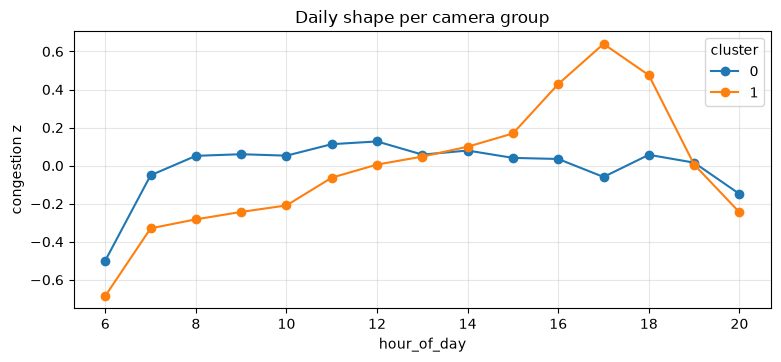

,cameras,mean_pcu,stations_500m,schools_500m,malls_500m
cluster,,,,,
0,61,7.92,0.48,3.08,2.84
1,39,6.60,0.51,2.08,3.03


In [4]:
prof = hourly.merge(cams[["camera_id", "cluster"]], on="camera_id").dropna(subset=["cluster"])
prof.groupby(["hour_of_day", "cluster"]).congestion_z.mean().unstack().plot(marker="o", title="Daily shape per camera group"); plt.ylabel("congestion z"); plt.show()
cams.groupby("cluster").agg(cameras=("camera_id", "size"), mean_pcu=("mean_pcu", "mean"), stations_500m=("n_stations_500m", "mean"),
                            schools_500m=("n_schools_500m", "mean"), malls_500m=("n_malls_500m", "mean")).round(2)

## 4. Rain
Rain comes from the nearest BMA rain gauge (median 0.85 km from the camera). The ERA5 model grid barely agrees with the gauges, which is why gauges are used.

gauge vs ERA5 hourly correlation: 0.20
            gauge_mm  era5_mm  rainy_hours
date                                      
2026-08-25      0.04     0.21           18
2026-08-26      0.00     0.12            0
2026-08-27      0.00     0.63            0
2026-08-28      0.02     0.79           68
2026-08-29      1.18     1.11          399
2026-08-30      0.60     0.30          295
2026-08-31      0.28     0.82          336


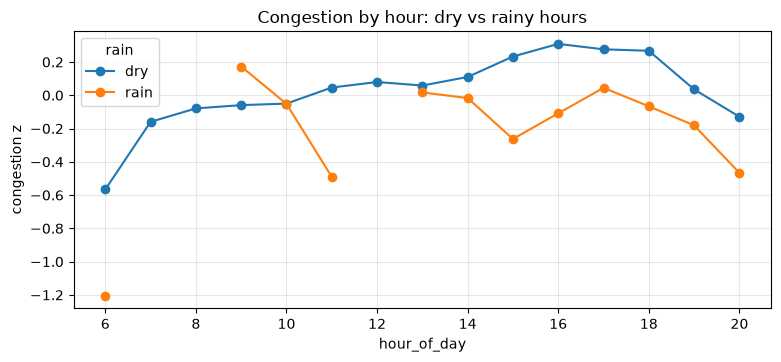

In [5]:
print("gauge vs ERA5 hourly correlation: %.2f" % hourly.precipitation.corr(hourly.era5_precipitation))
print(hourly.groupby("date").agg(gauge_mm=("precipitation", "mean"), era5_mm=("era5_precipitation", "mean"), rainy_hours=("precipitation", lambda s: (s >= .5).sum())).round(2))
h = hourly.dropna(subset=["precipitation", "congestion_z"]).copy()
h["rain"] = (h.precipitation >= 0.5).astype(int)
h.groupby(["hour_of_day", "rain"]).congestion_z.mean().unstack().rename(columns={0: "dry", 1: "rain"}).plot(marker="o", title="Congestion by hour: dry vs rainy hours"); plt.ylabel("congestion z"); plt.show()

### How much does rain change the counts?
Each row is one regression of a count on a rain dummy (gauge ≥ 0.5 mm in the hour), with standard errors clustered by camera.
- **base**: controls for hour of day × weekend and camera.
- **+ day effects**: also controls for the calendar day, so rain is compared with dry hours *on the same day*. This matters because almost all rain fell on Sat 29 – Mon 31 Aug.
- **daylight only**: 07–17, where YOLO is most reliable.

In [6]:
def effect(y, data, extra=""):
    f = smf.ols(f"{y} ~ rain + C(hour_of_day) * is_weekend + C(camera_id){extra}", data).fit(cov_type="cluster", cov_kwds={"groups": data.camera_id})
    lo, hi = f.conf_int().loc["rain"]
    return {"effect": f.params["rain"], "ci_low": lo, "ci_high": hi, "p": f.pvalues["rain"]}

# Day effects. Sunday shares the baseline label: the weekend terms already separate
# Sat+Sun from weekdays, so a dummy for both weekend days would be redundant (rank-deficient).
h["day"] = h.date.astype(str).where(h.weekday != "Sunday", "baseline")
h.loc[h.date == h.date.min(), "day"] = "baseline"
rows = {}
for y in ["congestion_z", "pcu", "n_car", "n_motorcycle", "n_bus", "n_person"]:
    rows[(y, "base")] = effect(y, h)
    rows[(y, "+ day effects")] = effect(y, h, " + C(day)")
    rows[(y, "+ day effects, daylight only")] = effect(y, h[h.hour_of_day.between(7, 17)], " + C(day)")
res = pd.DataFrame(rows).T
res["dry_mean"] = [h.loc[h.rain == 0, y].mean() for y, _ in res.index]
res.round(3)

effect  ci_low  ci_high      p  \
congestion_z base                          -0.183  -0.232   -0.133  0.000   
             + day effects                 -0.142  -0.195   -0.090  0.000   
             + day effects, daylight only  -0.055  -0.117    0.006  0.079   
pcu          base                          -0.578  -0.779   -0.378  0.000   
             + day effects                 -0.449  -0.671   -0.227  0.000   
             + day effects, daylight only  -0.217  -0.457    0.024  0.078   
n_car        base                          -0.482  -0.665   -0.299  0.000   
             + day effects                 -0.364  -0.565   -0.164  0.000   
             + day effects, daylight only  -0.144  -0.352    0.064  0.175   
n_motorcycle base                          -0.192  -0.253   -0.131  0.000   
             + day effects                 -0.197  -0.261   -0.133  0.000   
             + day effects, daylight only  -0.235  -0.304   -0.165  0.000   
n_bus        base                          -0.013  -0.034    0.007  0.202   
             + day effects                 -0.008  -0.031    0.016  0.508   
             + day effects, daylight only   0.002  -0.030    0.034  0.904   
n_person     base                          -0.258  -0.334   -0.182  0.000   
             + day effects                 -0.236  -0.310   -0.162  0.000   
             + day effects, daylight only  -0.229  -0.308   -0.149  0.000   

                                           dry_mean  
congestion_z base                             0.017  
             + day effects                    0.017  
             + day effects, daylight only     0.017  
pcu          base                             6.915  
             + day effects                    6.915  
             + day effects, daylight only     6.915  
n_car        base                             5.938  
             + day effects                    5.938  
             + day effects, daylight only     5.938  
n_motorcycle base                             0.701  
             + day effects                    0.701  
             + day effects, daylight only     0.701  
n_bus        base                             0.298  
             + day effects                    0.298  
             + day effects, daylight only     0.298  
n_person     base                             1.136  
             + day effects                    1.136  
             + day effects, daylight only     1.136

### Is it fewer vehicles, or YOLO seeing less?
`analysis/rain_check_sheets.py` puts a rainy and a dry image from the same camera side by side with YOLO's boxes (`data/rain_check/`). In the four sheets looked at so far: in a heavy downpour with haze YOLO missed about half the vehicles (camera 219); in lighter rain it found nearly all of them, and the kerbside parked cars and motorcycles really were gone. So part of the drop is real and part is missed detections. The hand count below puts a number on this.

If missed detections drove the result, the drop should grow with rain intensity. The table splits rainy hours by how hard it rained.

In [7]:
h["intensity"] = pd.cut(h.precipitation, [-1, .5, 2.5, 10, 1000], right=False, labels=["dry", "0.5-2.5 mm", "2.5-10 mm", "10+ mm"])
f = smf.ols("congestion_z ~ intensity + C(hour_of_day) * is_weekend + C(day)", h).fit(cov_type="cluster", cov_kwds={"groups": h.camera_id})
out = pd.DataFrame({"effect": f.params, "p": f.pvalues}).filter(like="intensity", axis=0).round(3)
out["hours"] = h.intensity.value_counts().reindex(["0.5-2.5 mm", "2.5-10 mm", "10+ mm"]).values
print(out)
print(h.groupby("rain")[["sharpness", "glare", "brightness"]].mean().round(2))

                         effect      p  hours
intensity[T.0.5-2.5 mm]  -0.127  0.000    733
intensity[T.2.5-10 mm]   -0.186  0.000    278
intensity[T.10+ mm]      -0.222  0.003     84
      sharpness  glare  brightness
rain                              
0         11.94   0.03      116.11
1         12.46   0.02      111.68


### Hand count against YOLO
100 images counted by hand, blind to YOLO's numbers (`analysis/hand_count.py`): dry daylight, measured rain, night, and images where YOLO reported 3+ trucks. In the hand count a pickup is a car and a truck has six wheels or more.

In [8]:
display(pd.read_csv("../export/hand_count_by_class.csv"), pd.read_csv("../export/hand_count_by_stratum.csv"))
hc = pd.read_csv("../export/hand_count_images.csv")
hc.groupby("stratum")[["motorcycle", "n_motorcycle", "person", "n_person"]].mean().round(2)

,class,hand_total,yolo_total,yolo_per_hand,mean_abs_error,correlation
0,car,1037,526,0.51,5.13,0.80
1,motorcycle,383,42,0.11,3.41,0.22
2,bus,23,21,0.91,0.20,0.56
3,truck,16,116,7.25,1.10,0.18
4,person,61,84,1.38,0.79,0.34


,stratum,images,pcu_hand,pcu_yolo,yolo_per_hand
0,dry day,40,13.78,8.22,0.60
1,many trucks,15,17.06,10.54,0.62
2,night,20,8.49,3.80,0.45
3,rain day,25,11.36,5.81,0.51


,motorcycle,n_motorcycle,person,n_person
stratum,,,,
dry day,4.68,0.52,0.52,0.90
many trucks,5.53,0.73,0.73,1.27
night,2.25,0.30,0.85,0.70
rain day,2.72,0.16,0.48,0.60


YOLO finds about 60% of cars (counting its "truck" as a car) and 11% of motorcycles; distant vehicles are a few pixels wide. Its truck class is mostly pickups (116 reported, 16 real), which is why the score counts it as a car. The score's level is too low but it ranks images well (correlation 0.86).

For rain: the hand count shows fewer motorcycles per image in rain (2.7 against 4.7 on dry days), so the direction of the finding holds, but YOLO's detection rate also falls in rain (6% against 11%), so the regression overstates the size. The hand count shows no drop in people, so that result is not confirmed. These strata use different cameras and few images: treat them as a rough check.

## 5. Air quality (weak evidence)
PM2.5 comes from the CAMS model grid (5 cells over the city), so it can only show the time pattern, not differences between roads.

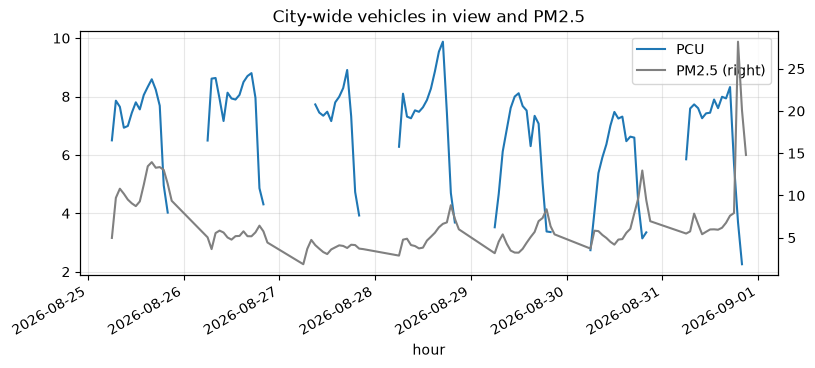

        pcu  pm2_5   no2
pcu    1.00  -0.30 -0.45
pm2_5 -0.30   1.00  0.89
no2   -0.45   0.89  1.00


In [9]:
city = hourly.groupby("hour").agg(pcu=("pcu", "mean"), pm2_5=("pm2_5", "mean"), no2=("nitrogen_dioxide", "mean"))
ax = city.pcu.plot(label="PCU", legend=True); city.pm2_5.plot(ax=ax, secondary_y=True, label="PM2.5", legend=True, color="grey"); plt.title("City-wide vehicles in view and PM2.5"); plt.show()
print(city.corr().round(2))

## 6. Limits
- One week, one weekend; rain on three consecutive days only.
- A photo counts vehicles in view, not speed: a jam and free flow can look alike, and stopped queues raise the count.
- YOLO11m is pretrained on COCO: it misses distant vehicles, more so at night and in heavy rain.
- Weather (other than rain) and air quality are model grids, not local measurements.